# Mitotic cell division simulation


## How mitotic-spindle cell division works

In a real epithelium a dividing cell does not split along an arbitrary line: the
orientation of the cleavage plane is set by the **mitotic spindle**, a bipolar
microtubule structure that orients itself inside the cell before cytokinesis. This
notebook reproduces that mechanism on a VertAX `BoundedMesh` in three stages — find the
spindle, cut along it, then relax the new tissue — and then chains them into a lineage of
successive divisions.

### 1. Finding the spindle — `spindle_model.find_spindle`

The spindle is modelled as **two centrosomes** held a fixed distance apart (a fraction
`d_fraction` of the cell's mean radius), connected to the cell cortex by **microtubules**.
Each microtubule pulls with a force proportional to the local **edge tension**, so
high-tension junctions pull harder; the cortical pull is integrated along every edge with
Gauss–Legendre quadrature (`n_gauss` points, via `_centrosome_force_jax`). The spindle
settles where the **net force and net torque on the two centrosomes vanish**:

$$F_1 + F_2 = 0, \qquad M_1 + M_2 = 0.$$

`find_spindle` returns the spindle **centre** `c` and **axis** `u`. Three strategies are
available through `method`:

- **`'newton'`** (default) — Newton–Raphson on the full force/torque balance;
  deterministic, and the centre may drift from the centroid.
- **`'pdf'`** — treats orientation as a Boltzmann-like density
  $p(\alpha)\propto\exp(-\bar V(\alpha)/C)$ and takes its **mode** (most probable angle).
- **`'pdf_sample'`** — draws a **random** orientation from that same density, modelling the
  experimental variability; `C` sets the noise level.

The microtubule density can additionally be biased by **cell polarity**
$\Lambda(\theta)=\sigma_j\,(1+p\cos^2(\theta-\varphi))$, so a polarised cell preferentially
orients its spindle along its polarity axis $\varphi$. (The PDF and polarity variants are
detailed in their own sections further down.)

### 2. Cutting the cell — `cell_division.divide_cell`

Given the spindle axis `u`, `divide_cell(mesh, face_id, c, u)` performs the **half-edge
topology surgery**: it intersects the cleavage line (perpendicular to the spindle axis,
as in real cytokinesis) with the cell boundary, inserts two new vertices at the crossings
plus a new edge between them, and rewires the half-edge table so one cell becomes two. It
returns the new mesh (one extra face) and the index of the new daughter cell.

### 3. Relaxing the tissue — `energy_adaptive` + `BoundedBilevelOptimizer`

Just after the cut the daughter cells are not mechanically balanced. We relax the mesh
with the standard bilevel optimizer (`inner_optimization`), minimising `energy_adaptive`
— which drives every cell toward a shared **target area** (total area ÷ number of cells)
while tension shortens edges — with **T1 transitions enabled** so neighbour exchanges can
occur as the geometry settles.

Repeating these three steps yields a **lineage of divisions**; the sections below run 5
consecutive divisions with the deterministic, PDF, stochastic, and polarity-biased
spindle variants.

In [ ]:
import importlib
import sys
sys.path.insert(0, '/home/mcorbeau/Bureau/vertax/src/vertax/mitotic_spindle')
import os
# os.environ.setdefault('JAX_PLATFORMS', 'cpu')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
os.environ.setdefault('JAX_ENABLE_X64', 'true')

# Run on GPU: jax[cuda12] is installed, but jax 0.4.35 crashes auto-detecting the
# CUDA path because the nvidia-cuda-nvcc-cu12 wheel is a namespace package
# (cuda_nvcc.__file__ is None). Setting CUDA_ROOT makes jax use it directly and
# skip the broken nvcc import. Points at the pip-installed nvcc dir (has bin/ptxas
# and nvvm/libdevice).
import sysconfig
_nvcc = os.path.join(sysconfig.get_paths()['purelib'], 'nvidia', 'cuda_nvcc')
if os.path.isdir(_nvcc):
    os.environ.setdefault('CUDA_ROOT', _nvcc)

# The inline backend crops figures with bbox_inches='tight' by default, which
# leaves a blank band above figures that use manually-placed axes (e.g. the
# side-by-side spindle plot). Disable that cropping so figures render as laid out.
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

import optax
import jax
print(jax.devices())
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from vertax import BoundedMesh, BoundedBilevelOptimizer, plot_mesh, get_plot_mesh
from vertax import EdgePlot, FacePlot, VertexPlot
from vertax.topo import update_T1_bounded

from mesh_utils import get_cell_segments
from spindle_model import find_spindle
from visualization import _plot_spindle_fig, _plot_spindle_pair, _plot_post_div_fig, _plot_opt_fig

import energy_adaptive; importlib.reload(energy_adaptive)
from energy_adaptive import energy_adaptive
import cell_division; importlib.reload(cell_division)
from cell_division import divide_cell
import visualization; importlib.reload(visualization)
from visualization import _plot_spindle_fig, _plot_spindle_pair, _plot_post_div_fig, _plot_opt_fig

In [9]:
import math

n_cells = 20
width = math.sqrt(n_cells)
height = width

mesh = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)


## Initial mesh and relaxation

Set per-element parameters (edge tensions, target areas) on the freshly seeded mesh, then
relax it with the bilevel optimizer using an **SGD** inner solver. The mesh is snapshotted
just before relaxation so the result can be shown **before / after** side by side.

In [10]:
mesh.vertices_params = jnp.asarray([0.0 for _ in range(mesh.nb_vertices)])

key = jax.random.PRNGKey(3)
mesh.edges_params = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh.nb_edges,)) * 20 - 10)

mesh.faces_params = jnp.asarray([0.6 for _ in range(mesh.nb_faces)])


In [ ]:
# Snapshot of the mesh BEFORE relaxation (for the before/after comparison plot).
mesh_initial = BoundedMesh.copy_mesh(mesh)

# Fix the common 'Area of cell' colour scale (used by every mesh plot in the
# notebook) to the raw initial mesh's area range.
import visualization
_init_areas = mesh_initial.get_area(jnp.arange(mesh_initial.nb_faces))
visualization.set_area_scale(float(_init_areas.min()), float(_init_areas.max()))

bilevel_optimizer = BoundedBilevelOptimizer()
bilevel_optimizer.loss_function_inner = energy_adaptive
bilevel_optimizer.inner_solver        = optax.sgd(learning_rate=1e-3)
bilevel_optimizer.update_T1           = True
bilevel_optimizer._update_T1_func     = update_T1_bounded
bilevel_optimizer.min_dist_T1         = 0.01
bilevel_optimizer.max_nb_iterations   = 1000
bilevel_optimizer.tolerance           = 1e-6
bilevel_optimizer.patience            = 50

loss_history = bilevel_optimizer.inner_optimization(mesh)

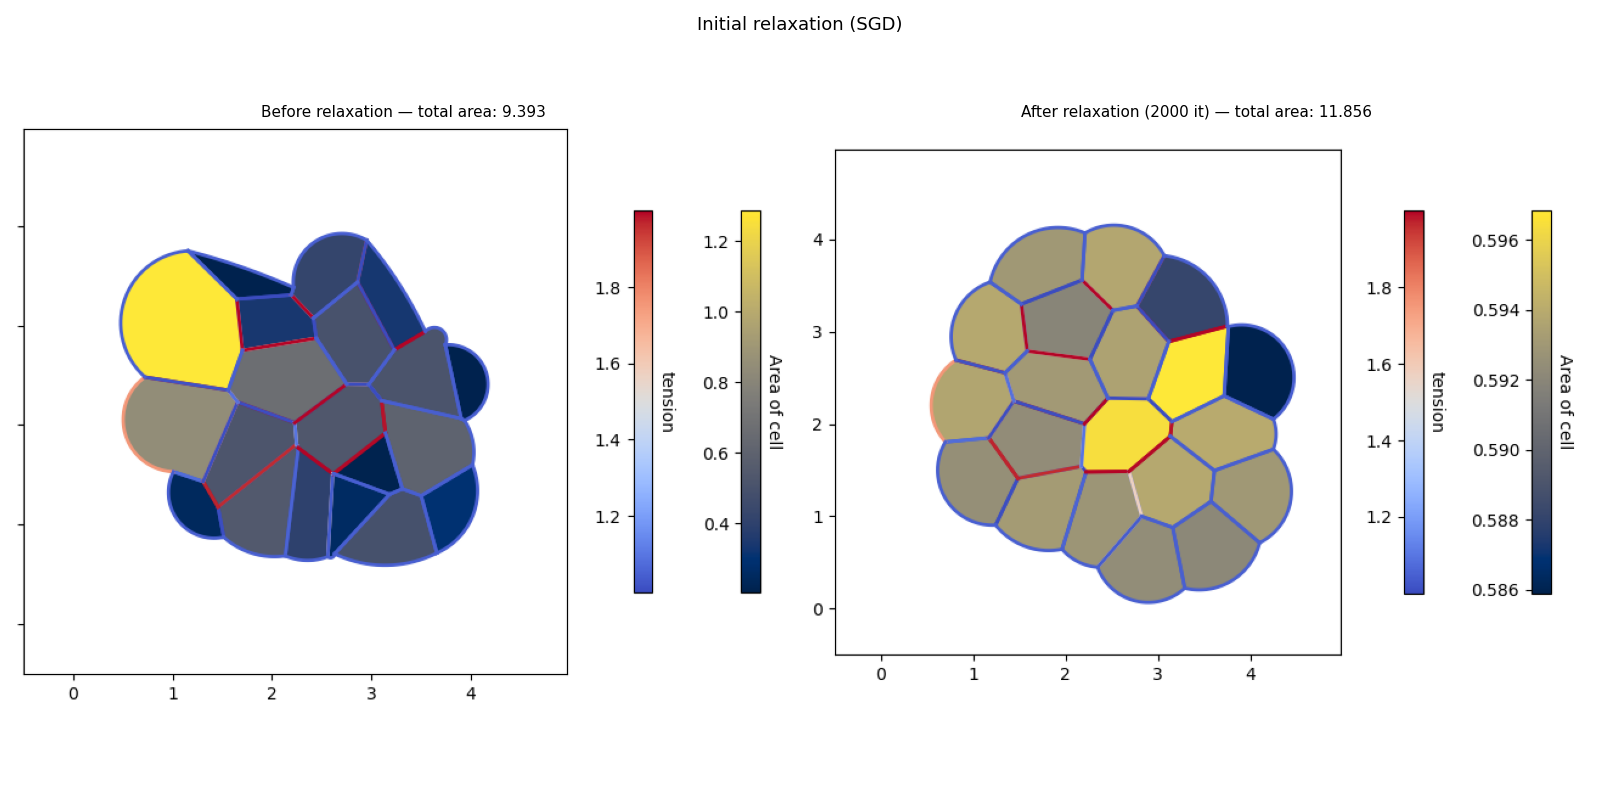

In [12]:
def _render_mesh(snap, title, ax):
    """Render a mesh (tension on edges, area on cells) into an existing axis."""
    m = BoundedMesh.copy_mesh(snap)
    m.angles = jnp.clip(m.angles, 0.017, jnp.pi / 2 - 0.01)
    fig_tmp, _ = get_plot_mesh(m,
                               edge_plot=EdgePlot.EDGE_PARAMETER, edge_parameters_name="tension",
                               face_plot=FacePlot.AREA,
                               vertex_plot=VertexPlot.INVISIBLE)
    fig_tmp.canvas.draw()
    w, h = fig_tmp.canvas.get_width_height()
    img = np.frombuffer(fig_tmp.canvas.tostring_argb(), dtype=np.uint8).reshape(h, w, 4)
    img = np.roll(img, -1, axis=2)  # ARGB -> RGBA
    plt.close(fig_tmp)
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")


area_before = float(jnp.sum(mesh_initial.get_area(jnp.arange(mesh_initial.nb_faces))))
area_after  = float(jnp.sum(mesh.get_area(jnp.arange(mesh.nb_faces))))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("Initial relaxation (SGD)", fontsize=13)
_render_mesh(mesh_initial, f"Before relaxation — total area: {area_before:.3f}", axes[0])
_render_mesh(mesh,         f"After relaxation ({len(loss_history)} it) — total area: {area_after:.3f}", axes[1])
plt.tight_layout()
plt.show()


## Mitotic spindle


In [13]:
import importlib
import spindle_model; importlib.reload(spindle_model)
import cell_division; importlib.reload(cell_division)
from spindle_model import find_spindle
from cell_division import divide_cell

# Find a divisible cell (spindle converges + exactly 2 cuts)
import numpy as np
rng = np.random.default_rng(0)
face_id = None
c = u = c1 = c2 = v0s = v1s = None
for fid in rng.permutation(mesh.nb_faces).tolist():
    try:
        from mesh_utils import get_cell_segments
        v0s_try, v1s_try, tensions_try = get_cell_segments(fid, mesh)
        c_try, u_try, c1_try, c2_try = find_spindle(fid, mesh, d_fraction=0.3, n_gauss=12)
        mesh_test = BoundedMesh.copy_mesh(mesh)
        divide_cell(mesh_test, fid, c_try, u_try)
        face_id, c, u, c1, c2 = fid, c_try, u_try, c1_try, c2_try
        v0s, v1s = v0s_try, v1s_try
        break
    except Exception as e:
        print(f"  face {fid} skipped: {e}")
        continue

if face_id is None:
    raise RuntimeError("No divisible cell found.")

print(f"Selected cell: {face_id}")
print(f"Center: ({c[0]:.4f}, {c[1]:.4f})")
print(f"Spindle axis u: ({u[0]:.4f}, {u[1]:.4f})")


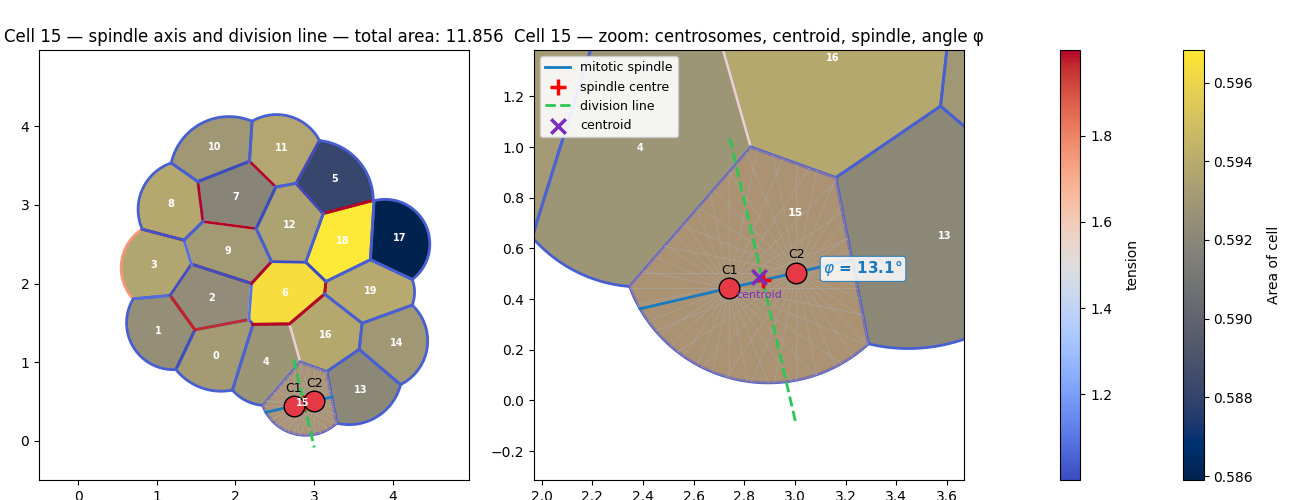

In [14]:
from visualization import _plot_spindle_pair
# Two views: the classic full-tissue plot, and a zoom on the dividing cell
# showing the two centrosomes (C1, C2), the geometric centroid, the mitotic
# spindle axis, and the angle φ.
_plot_spindle_pair(mesh, face_id, c, u, c1, c2, v0s, v1s)
plt.show()

## Cell division and relaxation

Cut the selected cell along the spindle axis, then relax the tissue with the bilevel
inner optimization. The mesh is shown **just after division** (left) and **after
relaxation** (right), side by side.

In [ ]:
mesh_post, _ = divide_cell(mesh, face_id, c, u)

print(f"Before: {mesh.nb_faces} cells")
print(f"After: {mesh_post.nb_faces} cells")

In [ ]:
mesh_opt = BoundedMesh.copy_mesh(mesh_post)
# Fixed per-cell target area: every cell relaxes towards 0.6 (no total-area target),
# so the tissue's total area grows as cells divide.
target_area = 0.6
mesh_opt.faces_params = jnp.full(mesh_opt.nb_faces, target_area)
print(f"Per-cell target area: {target_area:.4f} ({mesh_opt.nb_faces} cells "
      f"→ total target {target_area * mesh_opt.nb_faces:.4f})")

opt = BoundedBilevelOptimizer()
opt.loss_function_inner = energy_adaptive
opt.inner_solver        = optax.sgd(learning_rate=1e-3)
opt.update_T1           = True
opt._update_T1_func     = update_T1_bounded
opt.min_dist_T1         = 0.01
opt.max_nb_iterations   = 1000
opt.tolerance           = 1e-6
opt.patience            = 50

print(f"Before: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
loss_hist = opt.inner_optimization(mesh_opt)
print(f"After: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
print(f"{len(loss_hist)} iterations, loss = {float(loss_hist[-1]):.4f}")

In [ ]:
from visualization import _plot_div_relax_pair
# Left: mesh just after division.  Right: mesh after relaxation (inner optimization).
# Colour scales are taken from `mesh_initial` (the raw initial mesh, same scale as the
# "before relaxation" panel) so the areas/tensions are comparable across the notebook.
_plot_div_relax_pair(mesh_post, mesh_opt, division_idx=1, mesh_ref=mesh_initial)
plt.show()

## 5 consecutive divisions


In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

mesh_newton = BoundedMesh.copy_mesh(mesh)

mesh_final, division_snapshots = run_n_divisions(
    mesh_newton, n_divisions=5,
    cell_rng=np.random.default_rng(0),
)
print(f"Final tissue: {mesh_final.nb_faces} cells, {mesh_final.nb_edges} edges")


In [ ]:
from visualization import (_draw_mesh_on_ax, _add_cell_labels,
                           AREA_SCALE, TENSION_SCALE)
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area = ScalarMappable(Normalize(*AREA_SCALE), matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    """Add a tension + area colorbar pair to the right of one grid row. Labels are
    put on the LEFT of each bar so they never collide with the neighbouring bar."""
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area, ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.ax.yaxis.set_label_position("left")
        cb.set_label(lbl)


fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions  |  left: just after division  ·  right: after relaxation",
             fontsize=13)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots, start=1):
    row = div_idx - 1
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        # Common scales (tension = sigmoid(he_params)+1 ∈ [1,2]; area = initial mesh).
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} — area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

## Area decomposition of cells 21, 23, 10 (division 4, after relaxation)

The bounded-mesh area (`get_area_bounded`, Green's theorem) is the sum of two terms per
edge: a **shoelace** term over the chord vertices, and, for **boundary edges only**, the
**circular-segment** area between the chord and the arc (`chordlen² · f(angle)`). Below we
recompute that decomposition for cells 21, 23, 10 and draw each cell zoomed, showing the
edges actually used: **blue** = internal edges (straight chord, shoelace only), **red** =
boundary arc, **gray dashed** = the arc's chord.

In [ ]:
from vertax.meshes.plot import _get_arc_with_n_points
from vertax.geo import _compute_contributions

# Division 4, after relaxation.
_m_area = division_snapshots[3][1]

# Same tables get_area_bounded uses internally: vertTable prefixed with the two
# reserved rows [0,0] and [1,1], and per-half-edge angles. (Names are underscored
# to avoid clobbering globals used by other cells.)
_vtab = jnp.vstack([jnp.array([[0.0, 0.0], [1.0, 1.0]]), jnp.asarray(_m_area.vertices)])
_atab = jnp.repeat(jnp.asarray(_m_area.angles), 2)
_htab = jnp.asarray(_m_area.edges)
_E = np.array(_m_area.edges)
_Vp = np.array(_m_area.vertices)


def _he_chain(face):
    """Half-edges around a face, following the `next` pointer (col 1)."""
    start = int(_m_area.faces[face][0]); he = start; out = []
    for _ in range(60):
        out.append(he); he = int(_E[he][1])
        if he == start:
            break
    return out


def _decompose(face):
    """Shoelace + circular-segment split using vertax's own _compute_contributions,
    so the numbers match get_area_bounded exactly."""
    sh_t = 0.0; sg_t = 0.0
    for he in _he_chain(face):
        sh, sg = _compute_contributions(jnp.int32(he), _vtab, _atab, _htab)
        sh_t += float(sh); sg_t += float(sg)
    return 0.5 * abs(sh_t + sg_t), 0.5 * sh_t, 0.5 * sg_t


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, f in zip(axes, (21, 23, 10)):
    area, lace_a, seg_a = _decompose(f)
    api = float(_m_area.get_area(jnp.array([f]))[0])
    print(f"cell {f}: area={api:.4f}  | shoelace={lace_a:.4f}  circular-segment={seg_a:.4f}")
    # Draw the edges actually used: internal chords (blue), boundary arcs (red) + chord (gray).
    for he in _he_chain(f):
        internal = int(_E[he][3]) != 0
        vs = int(_E[he][3] + _E[he][5] - 2); vt_id = int(_E[he][4] + _E[he][6] - 3)
        if not (0 <= vs < len(_Vp) and 0 <= vt_id < len(_Vp)):
            continue
        p0, p1 = _Vp[vs], _Vp[vt_id]
        if internal:
            ax.plot([p0[0], p1[0]], [p0[1], p1[1]], "-", color="tab:blue", lw=2)
        else:
            ang = float(_m_area.angles[he // 2])
            arc = np.array(_get_arc_with_n_points(ang, p0, p1))
            pts = np.vstack([p0, arc, p1])
            ax.plot(pts[:, 0], pts[:, 1], "-", color="tab:red", lw=2)
            ax.plot([p0[0], p1[0]], [p0[1], p1[1]], "--", color="gray", lw=1)
        ax.scatter([p0[0]], [p0[1]], color="k", s=25, zorder=5)
    ax.set_aspect("equal")
    ax.set_title(f"cell {f}\narea={api:.4f}  (shoelace {lace_a:.3f} + arc {seg_a:.3f})", fontsize=10)

fig.suptitle("Area decomposition — blue: internal chord · red: boundary arc · gray dashed: arc chord",
             fontsize=12)
plt.show()

## 5 consecutive divisions — PDF method (mode)

### Orientation probability density

Following Théry et al., the division axis orientation $\alpha$ is governed by a Boltzmann-like probability density:

$$p(\alpha) = p_0 \exp\left(-\frac{\bar{V}(\alpha)}{C}\right)$$

where each term is:

| Symbol | Meaning |
|--------|---------|
| $\alpha \in [0, \pi]$ | Candidate spindle orientation (angle of axis $\mathbf{u} = (\cos\alpha, \sin\alpha)$) |
| $p_0$ | Normalisation constant such that $\int_0^\pi p(\alpha)\,d\alpha = 1$ |
| $C$ | Noise parameter (thermal fluctuations + nuclear friction); large $C$ → flat distribution |
| $\bar{V}(\alpha)$ | Dimensionless orientational potential (see below) |

**Orientational potential** $\bar{V}(\alpha)$ is the primitive of the normalised net torque $\bar{T}(\alpha)$:

$$\bar{V}(\alpha) = -\int_0^\alpha \bar{T}(\alpha')\,d\alpha'$$

**Normalised net torque** $\bar{T}(\alpha)$ at orientation $\alpha$:

$$\bar{T}(\alpha) = \frac{T(\alpha)}{r_N \cdot F_0}$$

where $T(\alpha) = M_1(\alpha) + M_2(\alpha)$ is the sum of moments exerted by the two centrosomes $C_1 = \mathbf{c} + d\,\mathbf{u}$ and $C_2 = \mathbf{c} - d\,\mathbf{u}$ on the cell boundary (computed by `_centrosome_force_jax`), $r_N$ is the nuclear radius, and $F_0$ a force scale. Since $r_N F_0$ is a global constant, it cancels in the exponential and we use $T(\alpha)$ directly.

**Numerical computation** (in `spindle_orientation_pdf`):
1. Sweep $\alpha \in [0, \pi]$ on a uniform grid of `pdf_n_alpha` = 180 points
2. Evaluate $T(\alpha)$ at each point via Gauss-Legendre quadrature (12 nodes per segment)
3. Integrate with the trapezoidal rule: $\bar{V}(\alpha_k) = -\sum_{i=0}^{k-1} \frac{T(\alpha_i)+T(\alpha_{i+1})}{2}\,\Delta\alpha$
4. Compute $p(\alpha) \propto \exp(-\bar{V}(\alpha)/C)$ and normalise

The `'pdf'` method selects the **mode** of $p(\alpha)$ — the most probable orientation — as the division axis. The spindle centre is fixed at the geometric centroid.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

# Start from the relaxed mesh so the PDF divisions begin from a
# mechanically equilibrated tissue, consistent with all other sections.
mesh_pdf = BoundedMesh.copy_mesh(mesh)

mesh_final_pdf, division_snapshots_pdf = run_n_divisions(
    mesh_pdf, n_divisions=5, spindle_method='pdf', spindle_pdf_C=0.1,
    cell_rng=np.random.default_rng(0),
)
print(f"Final tissue (pdf): {mesh_final_pdf.nb_faces} cells, {mesh_final_pdf.nb_edges} edges")


In [ ]:
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area = ScalarMappable(Normalize(*AREA_SCALE), matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area, ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.ax.yaxis.set_label_position("left")
        cb.set_label(lbl)


fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions (pdf mode)  |  left: just after division  ·  right: after relaxation",
             fontsize=13)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots_pdf, start=1):
    row = div_idx - 1
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} — area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

## 5 consecutive divisions — PDF method (stochastic sample)

The `'pdf_sample'` method uses the same density $p(\alpha)$ defined above, but **randomly draws** the division axis from that distribution rather than taking its mode.

This models the experimental observation that identical cells do not always divide along the same axis: the parameter $C$ quantifies the deviation from the deterministic equilibrium — larger $C$ makes atypical orientations more frequent.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

mesh_sample = BoundedMesh.copy_mesh(mesh)

mesh_final_sample, division_snapshots_sample = run_n_divisions(
    mesh_sample, n_divisions=5, spindle_method='pdf_sample', spindle_pdf_C=0.3,
    spindle_rng=np.random.default_rng(0),
    cell_rng=np.random.default_rng(0),
)
print(f"Final tissue (pdf_sample): {mesh_final_sample.nb_faces} cells, {mesh_final_sample.nb_edges} edges")


In [ ]:
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area = ScalarMappable(Normalize(*AREA_SCALE), matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area, ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.ax.yaxis.set_label_position("left")
        cb.set_label(lbl)


fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions (pdf_sample, C=0.3)  |  left: just after division  ·  right: after relaxation",
             fontsize=13)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots_sample, start=1):
    row = div_idx - 1
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} — area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

## Cell polarity bias on spindle orientation

### Biological motivation

In epithelial tissues, the mitotic spindle aligns not only with cell geometry (Hertwig's rule) but also with the planar polarity of the tissue. Planar cell polarity (PCP) is encoded in the asymmetric distribution of cortical tension: cells are pulled more strongly along certain directions by their junctions, creating a mechanical polarity axis. Experimental work by Théry et al. and Minc et al. shows that both geometry and tension polarity contribute to division axis selection — neither fully controls it.

### Polarity axis from the tension field

After each mechanical relaxation, the **polarity axis** $\varphi_f$ of cell $f$ is extracted from the tension-weighted edge-direction tensor:

$$\mathbf{T}_f = \sum_{e \in f} \sigma_e \,\hat{\mathbf{e}}_e \otimes \hat{\mathbf{e}}_e$$

where $\hat{\mathbf{e}}_e = (\mathbf{v}_1 - \mathbf{v}_0)/|\mathbf{v}_1 - \mathbf{v}_0|$ is the unit direction of junction $e$ and $\sigma_e = \text{sigmoid}(\theta_e) + 1$ is its tension (from `he_params`).

$\varphi_f$ is the angle of the **principal eigenvector** of $\mathbf{T}_f$ — the direction along which the cell is most strongly pulled.

### Polarity-biased microtubule density

The polarity axis biases spindle orientation by modulating the microtubule emission density:

$$\Lambda(\theta) = \sigma_j \cdot \bigl(1 + p \cos^2(\theta - \varphi_f)\bigr)$$

| Symbol | Meaning |
|--------|---------|
| $\theta$ | Emission direction of a microtubule ray |
| $\sigma_j$ | Tension of the membrane segment reached at angle $\theta$ |
| $\varphi_f$ | Polarity axis (principal tension eigenvector) |
| $p$ | `polarity_strength` $\in [0, 1]$ |

At $p = 0$ the model is identical to the geometry-only case (standard Newton / PDF methods). At $p = 1$, the microtubule density is doubled along $\varphi_f$ without suppressing other directions — the spindle remains free to align with cell geometry when it conflicts with polarity, matching the experimental observation that both cues contribute.

Polarity is recomputed from the tension field at each division step: no explicit tracking or inheritance is needed, since the mechanical state after relaxation encodes the tissue's history.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

# cell_rng is seeded identically so the same cells are chosen as in the
# Newton run (division_snapshots) — only the spindle orientation changes.
mesh_pol = BoundedMesh.copy_mesh(mesh)

print("Running 5 divisions WITH polarity bias (p=1.0)...")
mesh_final_pol, snaps_pol = run_n_divisions(
    mesh_pol, n_divisions=5, polarity_strength=1.0,
    cell_rng=np.random.default_rng(0),
)

print(f"With polarity: {mesh_final_pol.nb_faces} cells")


In [ ]:
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE),    matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area,    ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.ax.yaxis.set_label_position("left")
        cb.set_label(lbl)


fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions — PCP (polarity p=1.0)  |  left: just after division  ·  right: after relaxation",
             fontsize=13)

for div_idx, (snap_post, snap_opt) in enumerate(snaps_pol, start=1):
    row = div_idx - 1
    for col, (snap, label) in enumerate([
        (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
        (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} — area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()


## Comparison of division methods — post-division (pre-relaxation)

Each row is one division step (same cell chosen at each step across all methods,
`cell_rng=rng(0)`). The four columns show the tissue **just after the cut**, before
any relaxation, for each spindle model:

| Column | Method |
|--------|--------|
| 1 | Newton (deterministic force/torque balance) |
| 2 | PDF mode (most probable orientation) |
| 3 | PDF sample (stochastic draw from density) |
| 4 | PCP — polarity-biased Newton (p = 1.0) |


In [ ]:
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE),    matplotlib.colormaps["cividis"])


def _row_colorbars4(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.015, pad=0.02, aspect=15)
    cba = fig.colorbar(sm_area,    ax=row_axes, fraction=0.015, pad=0.05, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.ax.yaxis.set_label_position("left")
        cb.set_label(lbl)


methods = [
    (division_snapshots,     "Newton"),
    (division_snapshots_pdf, "PDF mode"),
    (division_snapshots_sample, "PDF sample"),
    (snaps_pol,              "PCP p=1.0"),
]

n_divs = min(len(s) for s, _ in methods)
fig, axes = plt.subplots(n_divs, 4, figsize=(28, 5 * n_divs))
fig.suptitle(
    "Division methods — post-division, pre-relaxation  "
    "|  cols: Newton · PDF mode · PDF sample · PCP (p=1.0)",
    fontsize=12,
)

for row, div_idx in enumerate(range(n_divs)):
    for col, (snaps, method_name) in enumerate(methods):
        snap_post, _ = snaps[div_idx]
        ax = axes[row, col]
        ta = float(jnp.sum(snap_post.get_area(jnp.arange(snap_post.nb_faces))))
        _draw_mesh_on_ax(snap_post, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap_post)
        ax.set_title(f"Div {div_idx + 1} — {method_name} ({snap_post.nb_faces}c) — area: {ta:.3f}",
                     fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars4(fig, axes[row, :])

plt.show()
